> **Aktualizace, 24. října.** Nasazený model je nyní model s měřeními dělenými proudem plazmatu (`analysis/clean_model.py`, `results/clean-model.md`). Tento notebook analyzuje `cand`, předchozí nasazený model: kde se píše „nasazený“, myslí se `cand` a čísla jsou čísla `cand`. Dnešní nasazený model se hodnotí v oddílu „Nasazený model dnes“ v notebooku 09.

# 07 Nerovnoměrné rozdělení a neobvyklé tvary: kde sedí chyba a co se stane s tvarem, který síť neviděla?

**Otázka (REQ-007 a bonus o neobvyklých tvarech).** Hodnoty parametrů plazmatu nejsou rozložené rovnoměrně: většina
řádků je obyčejná, menšina jsou limiterová plazmata, výboje s opačným znaménkem proudu, první a poslední
okamžiky výboje nebo vzácné tvary. (1) Jak nerovnoměrné cíle jsou? (2) Které skupiny řádků nesou chybu,
kterou hlavní průměr skrývá? (3) Co jsme s tím udělali a kolik to stálo? (4) O kolik je síť horší na rodině
tvarů, na kterých se neučila?

Tento notebook **nepotřebuje data**. Čísla čte z agregovaných souborů uložených v `results/`
(`data-checks.md`, `distribution.md`, `unusual-shapes.md`, `signcanon.md`, `final-evaluation.md`); nečte se žádný řádek dat ÚFP
a nic se neučí, takže proběhne od začátku do konce na čistém checkoutu za pár vteřin (potřebuje `numpy pandas matplotlib`).
Měření provedly skripty v `analysis/` na důvěrných datech; každá tabulka níže uvádí protokol, z něhož
pochází. Čísla v textu se generují z přečtených souborů.

Objevují se dva protokoly a nikdy se nemíchají v jednom čísle:

| název | co to je | použito pro |
|---|---|---|
| **P1, mimo učicí sadu** | základní síť (256-256-128, 24 vstupů, 60 epoch), 5 foldů dělených po celých výbojích, predikce odložených výbojů sloučené přes všech 149 výbojů (42 972 řádků) | oddíly 2, 3 a 5 |
| **P2, vývojová a odložená sada** | 119 vývojových výbojů (uvnitř 5 foldů) a 30 odložených výbojů (8 761 řádků), hodnoceno jednou pro každý konečný model; receptury v `final-evaluation.md` | oddíl 4 |

Chyby jsou průměrné absolutní rozdíly (MAE) od referenční rekonstrukce (rekonstrukce rovnováhy ústavu, která dává štítky, ne nezávislé měření plazmatu) v jednotce cíle: mm pro polohy, kA pro proud plazmatu.

In [1]:
import re, json, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown as _Markdown, display

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

# Tento notebook čte jen soubory uložené v results/ (tabulky, json, png); nepotřebuje data ÚFP ani žádné učení.
here = Path.cwd().resolve()
repo = next((p for p in [here, *here.parents] if (p / "results" / "final-evaluation.md").exists()), None)
if repo is None:
    raise SystemExit("Spusťte z vnitřku repozitáře: results/final-evaluation.md nebyl nalezen")
RES = repo / "results"
READ = set()  # každý soubor s výsledky, který notebook otevře; na konci se zkontroluje proti `git ls-files`


def read(name):
    READ.add(name)
    return (RES / name).read_text()


def num(x):
    """První číslo v buňce: '44.2%' -> 44.2, '1.2 [0.9, 1.4]' -> 1.2, '0.53 to 1.10 (2.1x)' -> 0.53, 'n/a' -> nan."""
    m = re.search(r"-?\d+(?:\.\d+)?(?:e[+-]?\d+)?", str(x).replace(",", ""))
    return float(m.group()) if m else np.nan


def md_tables(name):
    """Všechny tabulky s rourami ze souboru markdown s výsledky jako (nejbližší nadpis nad nimi, DataFrame řetězců)."""
    out, heading, cur = [], "", None
    for line in read(name).splitlines():
        if line.startswith("#"):
            heading, cur = line.lstrip("# ").strip(), None
        elif line.startswith("|"):
            cells = [c.strip() for c in line.strip().strip("|").split("|")]
            if cur is None:
                cur = {"heading": heading, "header": cells, "rows": []}
                out.append(cur)
            elif not set("".join(cells)) <= set("-: "):
                cur["rows"].append(cells)
        else:
            cur = None
    return [(t["heading"], pd.DataFrame(t["rows"], columns=t["header"])) for t in out]


def table(name, heading=None, has=None, nth=0):
    """N-tá tabulka, jejíž nadpis začíná `heading` a jejíž hlavička obsahuje každý sloupec z `has`."""
    hits = [df for h, df in md_tables(name)
            if (heading is None or h.startswith(heading)) and all(c in df.columns for c in (has or []))]
    if len(hits) <= nth:
        raise KeyError(f"{name}: no table for heading={heading!r} has={has!r}")
    return hits[nth]


def numeric(df, text=("target", "unit")):
    """Index podle prvního sloupce a převod každého dalšího sloupce na float (textové sloupce zůstanou řetězce)."""
    df = df.copy()
    if "unit" in df.columns:
        df["unit"] = df["unit"].replace("", "-")  # cíle bez jednotky: soubory s výsledky nechávají buňku prázdnou
    for c in df.columns[1:]:
        if c not in text:
            df[c] = df[c].map(num).astype(float)
    return df.set_index(df.columns[0])


def section(name, heading):
    """Řádky oddílu `## heading...` (do dalšího `## `), tak jak jsou napsané v souboru s výsledky."""
    lines, on = [], False
    for line in read(name).splitlines():
        if line.startswith("## "):
            on = line[3:].startswith(heading)
            continue
        if on:
            lines.append(line)
    if not lines:
        raise KeyError(f"{name}: no section {heading!r}")
    return "\n".join(lines).strip()


def show(df, proto, fmt="{:.3g}"):
    """Vytiskne tabulku s protokolem, za kterého se měřila, těsně nad ní."""
    print("Protokol:", proto)
    print(df.to_string(float_format=lambda v: fmt.format(v)))
    print()


def cz(text):
    """České číslování v generovaném textu: desetinná čárka místo tečky, mezera jako oddělovač tisíců."""
    text = re.sub(r"(?<![\d,.])([1-9]\d{0,2}),(\d{3})\b", "\\1\u00a0\\2", text)
    return re.sub(r"(?<=\d)\.(?=\d)", ",", text)


def Markdown(text):
    """Vygenerovaný text s českými čísly (citace ze souborů s výsledky jdou přes _Markdown beze změny)."""
    return _Markdown(cz(text))


def quote(text, source):
    display(_Markdown(f"*Citováno z `results/{source}`:*\n\n" + text))


def tracked_check():
    """Seznam souborů, které nejsou pod správou gitu (a počet přečtených); každý otevřený soubor s výsledky musí být v gitu, ne jen lokální pracovní soubor."""
    out = subprocess.run(["git", "-C", str(repo), "ls-files", "results"], capture_output=True, text=True)
    tracked = {Path(p).name for p in out.stdout.split()}
    missing = sorted(f for f in READ if f not in tracked)
    return missing, len(READ), bool(tracked)


print("repozitář:", repo.name, "| složka s výsledky:", RES.relative_to(repo))

repozitář: hackathon | složka s výsledky: results


## 1. Jak nerovnoměrné jsou cíle?

`data-checks.md` uvádí pro každý cíl směrodatnou odchylku a šířku pásu, který drží 98 % hodnot.
Při normálním rozdělení by ten pás byl široký 4,65 směrodatné odchylky. Pás mnohem užší znamená,
že směrodatnou odchylku natahuje několik vzácných hodnot. Poměr je naše vlastní podělení dvou uložených sloupců.

Protokol: všech 149 výbojů, každý řádek, kde cíl existuje (souhrn z `analysis/data_checks.py`)
                    unit  standard deviation  98 percent band width  band_over_sd
target                                                                           
plasma_current        kA                 114                    543          4.75
R_mag_axis            mm                8.02                   42.3          5.27
Z_mag_axis            mm                13.7                   56.4          4.11
elongation             -               0.271                  0.836          3.09
triangularity          -               0.119                  0.424          3.55
triangularity_upper    -              0.0749                    0.3             4
triangularity_lower    -               0.172                  0.598          3.47
R_x_point             mm                8.06                   38.2          4.74
Z_x_point             mm                12.7                   49.9          3.92
R_s

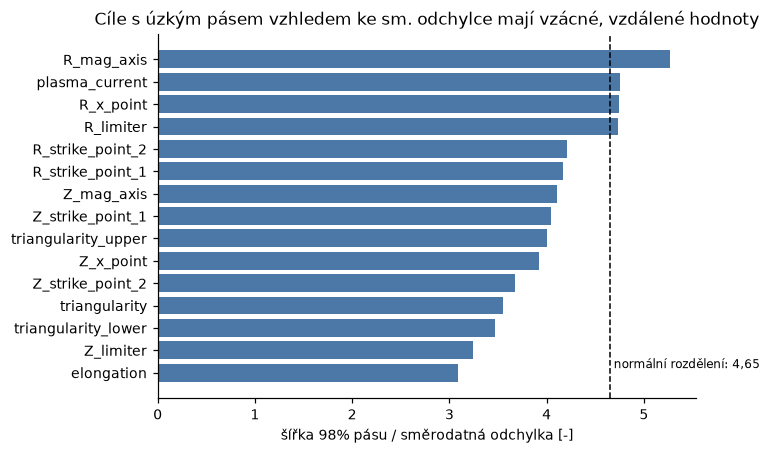

**Čtení.** Rozptyl je malý jen u magnetické osy, X bodu a dotykových bodů: směrodatná odchylka 2,4 až 13,7 mm. Bod limiteru se pohybuje o 90 mm (R) a 153 mm (Z) a proud plazmatu o 114 kA, proto se chyby vždy uvádějí ve fyzikálních jednotkách a vedle rozptylu. 98 % hodnot osy leží v pásu o šířce 42,3 mm (R) a 56,4 mm (Z). Směrodatná odchylka elongace je 1,51krát tolik, kolik naznačuje její 98% pás: odpovídá to malé skupině výbojů s velmi odlišným tvarem (oddíl 5).

In [2]:
F_CHK = "data-checks.md"
spread = numeric(table(F_CHK, "Spread of the targets"))
spread["band_over_sd"] = spread["98 percent band width"] / spread["standard deviation"]
show(spread, "všech 149 výbojů, každý řádek, kde cíl existuje (souhrn z `analysis/data_checks.py`)")

fig, ax = plt.subplots(figsize=(7, 4.2))
order = spread["band_over_sd"].sort_values().index
ax.barh(order, spread.loc[order, "band_over_sd"], color="#4c78a8")
ax.axvline(4.653, color="k", ls="--", lw=1)
ax.text(4.69, 0.2, "normální rozdělení: 4,65", fontsize=8)
ax.set_xlabel("šířka 98% pásu / směrodatná odchylka [-]")
ax.set_title("Cíle s úzkým pásem vzhledem ke sm. odchylce mají vzácné, vzdálené hodnoty")
plt.tight_layout(); plt.show()

small = ["R_mag_axis", "Z_mag_axis", "R_x_point", "Z_x_point", "R_strike_point_1", "Z_strike_point_1", "R_strike_point_2", "Z_strike_point_2"]
sd_small = spread.loc[small, "standard deviation"]
display(Markdown(
    f"**Čtení.** Rozptyl je malý jen u magnetické osy, X bodu a dotykových bodů: směrodatná odchylka "
    f"{sd_small.min():.1f} až {sd_small.max():.1f} mm. Bod limiteru se pohybuje o {spread.loc['R_limiter','standard deviation']:.0f} mm (R) a "
    f"{spread.loc['Z_limiter','standard deviation']:.0f} mm (Z) a proud plazmatu o {spread.loc['plasma_current','standard deviation']:.0f} kA, "
    f"proto se chyby vždy uvádějí ve fyzikálních jednotkách a vedle rozptylu. 98 % hodnot osy leží v pásu o šířce "
    f"{spread.loc['R_mag_axis','98 percent band width']:.1f} mm (R) a {spread.loc['Z_mag_axis','98 percent band width']:.1f} mm (Z). "
    f"Směrodatná odchylka elongace je {1/spread.loc['elongation','band_over_sd']*4.653:.2f}krát tolik, kolik naznačuje její 98% pás: "
    f"odpovídá to malé skupině výbojů s velmi odlišným tvarem (oddíl 5)."))

## 2. Kde chyba sedí (protokol P1)

Zdroj: `distribution.md`, vytvořil `analysis/distribution.py` z predikcí základní sítě mimo učicí sadu.
Nic se tu neučí. Každá skupina se ukazuje se dvěma podíly: `rows` je její podíl řádků a `sq err` její podíl na celkové
čtvercové chybě daného cíle. Kde je `sq err` daleko nad `rows`, nese chybu menšina.

Protokol: baseline MLP 256-256-128 on 24 inputs, 60 epochs, 5-fold GroupKFold by discharge, out-of-fold, 42,972 rows of 149 discharges (`distribution.md`); průměr, medián a percentily chvostu absolutní chyby
                 unit     MAE  median    p95   p99   max  nRMSE
target                                                         
plasma_current     kA    1.49   0.747   4.38  15.9  91.4 0.0297
R_mag_axis         mm   0.377   0.153   1.21  3.74  64.3  0.156
Z_mag_axis         mm   0.391    0.18   1.33  3.55   284  0.125
elongation          - 0.00569 0.00301 0.0188 0.044 0.493 0.0429
R_x_point          mm   0.203  0.0755  0.615  3.15  20.5 0.0774
R_strike_point_1   mm   0.265   0.112  0.754  3.55  15.1 0.0653
R_limiter          mm    10.8    2.64     49   145   378  0.318
Z_limiter          mm    22.3    9.32   90.9   171   512  0.273



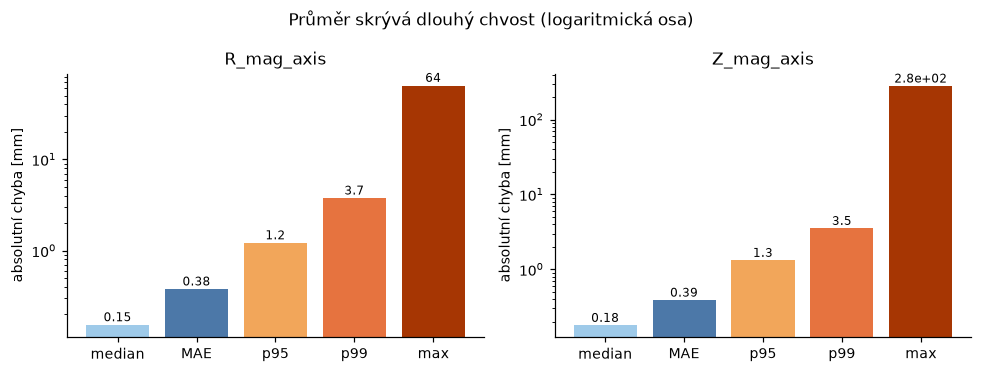

In [3]:
F_DIST = "distribution.md"
P1 = ("baseline MLP 256-256-128 on 24 inputs, 60 epochs, 5-fold GroupKFold by discharge, out-of-fold, 42,972 rows of 149 discharges "
      "(`distribution.md`)")
overall = numeric(table(F_DIST, "Overall, for reference"))
head = ["plasma_current", "R_mag_axis", "Z_mag_axis", "elongation", "R_x_point", "R_strike_point_1", "R_limiter", "Z_limiter"]
show(overall.loc[head, ["unit", "MAE", "median", "p95", "p99", "max", "nRMSE"]], P1 + "; průměr, medián a percentily chvostu absolutní chyby")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=False)
for ax, t in zip(axes, ["R_mag_axis", "Z_mag_axis"]):
    vals = overall.loc[t, ["median", "MAE", "p95", "p99", "max"]]
    ax.bar(vals.index, vals.values, color=["#9ecae9", "#4c78a8", "#f2a65a", "#e6733f", "#a63603"])
    ax.set_yscale("log"); ax.set_title(t); ax.set_ylabel("absolutní chyba [mm]")
    for i, v in enumerate(vals.values): ax.text(i, v * 1.1, f"{v:.2g}", ha="center", fontsize=8)
plt.suptitle("Průměr skrývá dlouhý chvost (logaritmická osa)"); plt.tight_layout(); plt.show()

### 2.1 Limiterové proti divertorovému plazmatu

Plazma je buď divertorové (má X bod a dotykové body), nebo limiterové (dotýká se stěny v bodě limiteru).
Limiterové řádky jsou menšina a těžší případ.

Protokol: baseline MLP 256-256-128 on 24 inputs, 60 epochs, 5-fold GroupKFold by discharge, out-of-fold, 42,972 rows of 149 discharges (`distribution.md`); limiterové = `is_limited` podle referenční rekonstrukce; rows a sq err v %
                    unit  MAE limited  MAE diverted  rows limited  sq err limited  MAE ratio limited/diverted
target                                                                                                       
plasma_current        kA         2.01          1.07          44.2            77.9                        1.88
R_mag_axis            mm        0.553         0.237          44.2            91.9                        2.33
Z_mag_axis            mm        0.516         0.293          44.2            94.3                        1.76
elongation             -      0.00815       0.00373          44.2            80.4                        2.18
triangularity          -      0.00415        0.0018          44.2            84.1                        2.31

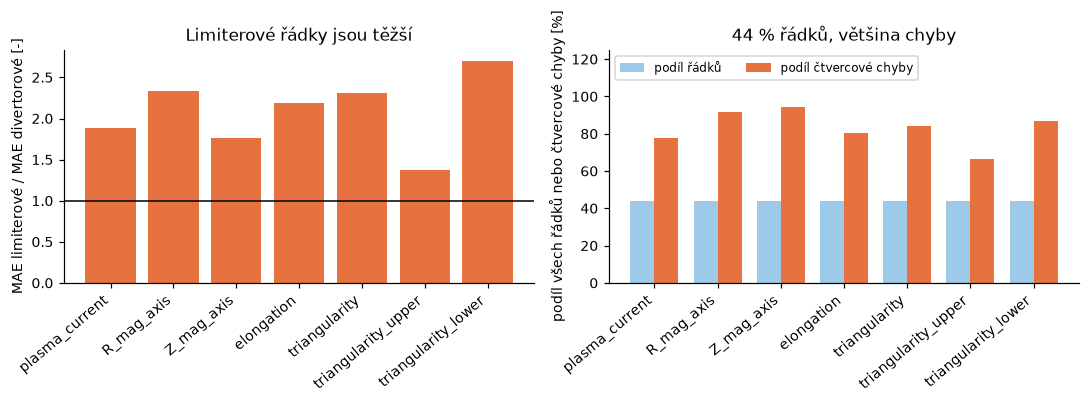

In [4]:
cfg = numeric(table(F_DIST, "By configuration"))
t7 = ["plasma_current", "R_mag_axis", "Z_mag_axis", "elongation", "triangularity", "triangularity_upper", "triangularity_lower"]
c = cfg.loc[t7, ["unit", "MAE limited", "MAE diverted", "rows limited", "sq err limited"]].copy()
c["MAE ratio limited/diverted"] = c["MAE limited"] / c["MAE diverted"]
show(c, P1 + "; limiterové = `is_limited` podle referenční rekonstrukce; rows a sq err v %")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].bar(c.index, c["MAE ratio limited/diverted"], color="#e6733f"); axes[0].axhline(1, color="k", lw=1)
axes[0].set_ylabel("MAE limiterové / MAE divertorové [-]"); axes[0].set_title("Limiterové řádky jsou těžší")
x = np.arange(len(c)); w = 0.38
axes[1].bar(x - w/2, c["rows limited"], w, label="podíl řádků", color="#9ecae9")
axes[1].bar(x + w/2, c["sq err limited"], w, label="podíl čtvercové chyby", color="#e6733f")
axes[1].set_ylabel("podíl všech řádků nebo čtvercové chyby [%]"); axes[1].set_title(f"{c['rows limited'].iloc[0]:.0f} % řádků, většina chyby"); axes[1].set_ylim(0, 125); axes[1].legend(fontsize=8, ncol=2, loc="upper left")
for ax in axes: ax.set_xticks(range(len(c))); ax.set_xticklabels(c.index, rotation=40, ha="right")
plt.tight_layout(); plt.show()

### 2.2 Obrácený (kladný) proud plazmatu

16 ze 149 výbojů má v souboru kladný proud plazmatu, všechny ostatní záporný (`positive current` níže; 92,6 % řádků je záporných). Konvence znaménka a její vztah k toroidálnímu poli v tomto repozitáři zaznamenané nejsou, takže nevíme, zda jde o výboje opačné polarity stroje; „obrácené“ níže znamená jen „s kladným znaménkem“.
Foldy nebyly stratifikované podle polarity, takže těchto 16 výbojů je mezi foldy rozloženo také nerovnoměrně.

Protokol: baseline MLP 256-256-128 on 24 inputs, 60 epochs, 5-fold GroupKFold by discharge, out-of-fold, 42,972 rows of 149 discharges (`distribution.md`); obrácené = kladný průměrný proud plazmatu (16 výbojů), obvyklé = záporný
                 unit  MAE reversed  MAE usual  rows reversed %  sq err reversed %  MAE ratio reversed/usual
target                                                                                                      
plasma_current     kA          3.62       1.32              7.4                 26                      2.74
R_mag_axis         mm          1.73      0.269              7.4               77.8                      6.43
Z_mag_axis         mm          1.38      0.312              7.4               86.6                      4.42
elongation          -        0.0174    0.00475              7.4               51.6                      3.66
R_x_point          mm          1.36      0.123              6.4               83.8                      11.1
R_strike

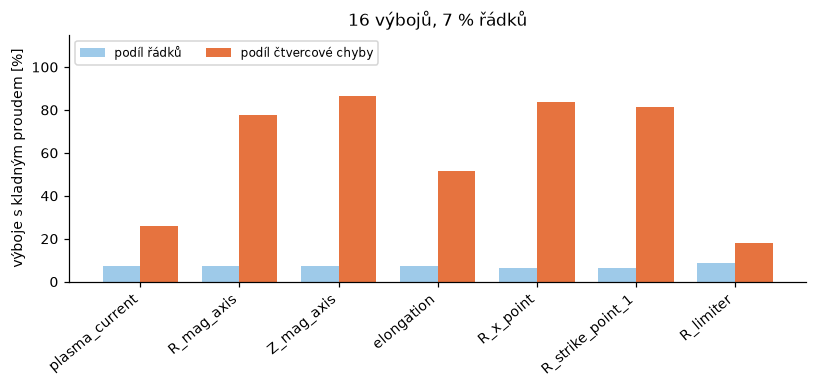

In [5]:
pol = numeric(table(F_DIST, "By current polarity"))
n_pos = int(re.search(r"(\d+) of 149 discharges are positive", read(F_DIST)).group(1))
assert n_pos == 16, n_pos  # markdown výše cituje 16
tp = ["plasma_current", "R_mag_axis", "Z_mag_axis", "elongation", "R_x_point", "R_strike_point_1", "R_limiter"]
p = pol.loc[tp, ["unit", "MAE positive current", "MAE negative current", "rows positive current", "sq err positive current"]].copy()
p.columns = ["unit", "MAE reversed", "MAE usual", "rows reversed %", "sq err reversed %"]
p["MAE ratio reversed/usual"] = p["MAE reversed"] / p["MAE usual"]
show(p, P1 + "; obrácené = kladný průměrný proud plazmatu (16 výbojů), obvyklé = záporný")

fig, ax = plt.subplots(figsize=(7.5, 3.6)); x = np.arange(len(p)); w = 0.38
ax.bar(x - w/2, p["rows reversed %"], w, label="podíl řádků", color="#9ecae9")
ax.bar(x + w/2, p["sq err reversed %"], w, label="podíl čtvercové chyby", color="#e6733f")
ax.set_xticks(x); ax.set_xticklabels(p.index, rotation=40, ha="right"); ax.set_ylabel("výboje s kladným proudem [%]")
ax.set_title(f"{n_pos} výbojů, {p['rows reversed %'].iloc[0]:.0f} % řádků"); ax.set_ylim(0, 115); ax.legend(fontsize=8, ncol=2, loc="upper left"); plt.tight_layout(); plt.show()

### 2.3 První a poslední okamžiky výboje

Na obou koncích chyba roste. Důvod není zjištěn: proud plazmatu je tam malý a rychle se mění, takže samotná referenční rekonstrukce tam může být nejméně spolehlivá (hypotéza, netestováno), a pak tabulka ukazuje neshodu se štítkem, který je na koncích nejslabší.

Protokol: baseline MLP 256-256-128 on 24 inputs, 60 epochs, 5-fold GroupKFold by discharge, out-of-fold, 42,972 rows of 149 discharges (`distribution.md`); první a poslední 2 % relativního času každého výboje (asi 925 řádků v každé)
           unit  MAE first 2 %  MAE middle 96 %  MAE last 2 %  sq err first 2 %  sq err last 2 %  first/middle  last/middle
target                                                                                                                     
R_mag_axis   mm           1.54            0.321           1.7              23.4             26.9           4.8          5.3
Z_mag_axis   mm           1.38            0.335          1.91               7.2             77.9          4.12          5.7
elongation    -        0.00773          0.00543        0.0151               2.1             19.8          1.42         2.78
R_x_point    mm            NaN            0.202         0.313               NaN              0.9           NaN         1.55
R_limiter    mm        

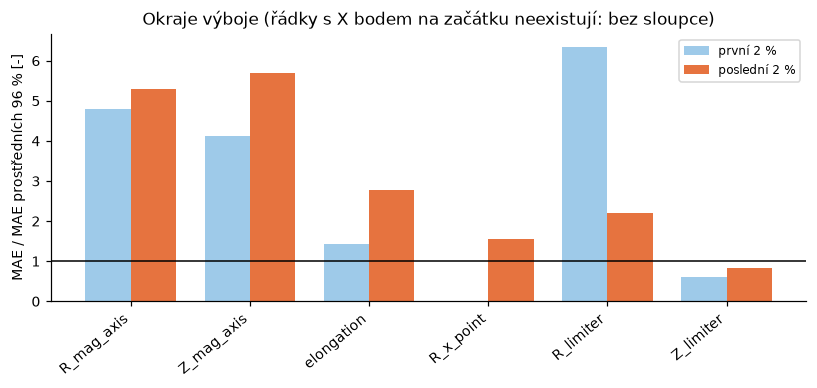

In [6]:
pos = numeric(table(F_DIST, "By position in the discharge"))
tq = ["R_mag_axis", "Z_mag_axis", "elongation", "R_x_point", "R_limiter", "Z_limiter"]
q = pos.loc[tq, ["unit", "MAE first 2 %", "MAE middle 96 %", "MAE last 2 %", "sq err first 2 %", "sq err last 2 %"]].copy()
q["first/middle"] = q["MAE first 2 %"] / q["MAE middle 96 %"]
q["last/middle"] = q["MAE last 2 %"] / q["MAE middle 96 %"]
show(q, P1 + "; první a poslední 2 % relativního času každého výboje (asi 925 řádků v každé)")

fig, ax = plt.subplots(figsize=(7.5, 3.6)); x = np.arange(len(q)); w = 0.38
ax.bar(x - w/2, q["first/middle"], w, label="první 2 %", color="#9ecae9"); ax.bar(x + w/2, q["last/middle"], w, label="poslední 2 %", color="#e6733f")
ax.axhline(1, color="k", lw=1); ax.set_xticks(x); ax.set_xticklabels(q.index, rotation=40, ha="right")
ax.set_ylabel("MAE / MAE prostředních 96 % [-]"); ax.set_title("Okraje výboje (řádky s X bodem na začátku neexistují: bez sloupce)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 2.4 Vzácné hodnoty cílů

Řádky se rozdělí na pět stejných skupin podle referenční hodnoty každého cíle (kvintily; Q1 nejnižší). Cíl, jehož chyba roste na kraji, je cíl, jehož
vzácné hodnoty se odhadují hůř.

hranice kvintilů referenční hodnoty R_mag_axis [mm]: Q1: 462.3 to 555.1; Q2: 555.1 to 559.9; Q3: 559.9 to 563.2; Q4: 563.2 to 566; Q5: 566 to 674.1


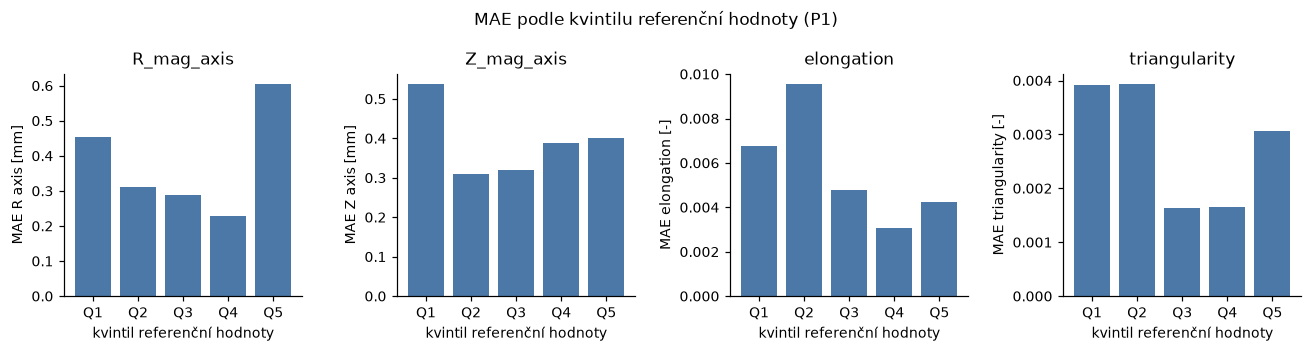

**Čtení.** Nejhorší skupina řádků podle referenční hodnoty je R_mag_axis: nejhorší Q5 (0,604), nejlepší Q4 (0,228), poměr 2,6; Z_mag_axis: nejhorší Q1 (0,537), nejlepší Q2 (0,31), poměr 1,7; elongation: nejhorší Q2 (0,00954), nejlepší Q4 (0,00309), poměr 3,1; triangularity: nejhorší Q2 (0,00393), nejlepší Q3 (0,00163), poměr 2,4. Radiální osa je horší na obou koncích; elongace je nejhorší ve druhém kvintilu, kde leží nízké hodnoty neobvyklých tvarů (oddíl 5); soubor ten kvintil dál nedělí.

In [7]:
quint = {}
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, (h, label) in zip(axes, [("R_mag_axis (mm)", "R axis [mm]"), ("Z_mag_axis (mm)", "Z axis [mm]"), ("elongation", "elongation [-]"), ("triangularity", "triangularity [-]")]):
    qt = numeric(table(F_DIST, h, has=["quintile"]).rename(columns={"quintile": "q"}), text=("range of the true value",))
    quint[h.split(" (")[0]] = qt
    ax.bar(qt.index, qt["MAE"], color="#4c78a8")
    ax.set_title(h.split(" (")[0]); ax.set_ylabel(f"MAE {label}"); ax.set_xlabel("kvintil referenční hodnoty")
    if h == "R_mag_axis (mm)": print("hranice kvintilů referenční hodnoty R_mag_axis [mm]:", "; ".join(f"{i}: {r}" for i, r in qt["range of the true value"].items()))
plt.suptitle("MAE podle kvintilu referenční hodnoty (P1)"); plt.tight_layout(); plt.show()
parts = []
for t, qt in quint.items():
    w, b = qt["MAE"].idxmax(), qt["MAE"].idxmin()
    parts.append(f"{t}: nejhorší {w} ({qt.loc[w,'MAE']:.3g}), nejlepší {b} ({qt.loc[b,'MAE']:.3g}), poměr {qt.loc[w,'MAE']/qt.loc[b,'MAE']:.1f}")
display(Markdown("**Čtení.** Nejhorší skupina řádků podle referenční hodnoty je " + "; ".join(parts) + ". Radiální osa je horší na obou koncích; elongace je nejhorší ve druhém kvintilu, "
                 "kde leží nízké hodnoty neobvyklých tvarů (oddíl 5); soubor ten kvintil dál nedělí."))

### 2.5 Oddíl Limits ve zprávě, ověřený proti tabulkám

`distribution.md` končí oddílem Limits. Jeho znění se ukáže tak, jak je napsané, a každé číslo v něm se porovná s právě přečtenou hodnotou z tabulky.

In [8]:
limits = section(F_DIST, "Limits")
quote(limits, F_DIST)
checks = {
    "limited share of rows": f"{cfg.loc['R_mag_axis', 'rows limited']:.1f}%",
    "limited share of squared R axis error": f"{cfg.loc['R_mag_axis', 'sq err limited']:.1f}%",
    "reversed share of rows": f"{pol.loc['R_mag_axis', 'rows positive current']:.1f}%",
    "reversed share of squared R axis error": f"{pol.loc['R_mag_axis', 'sq err positive current']:.1f}%",
    "R_limiter MAE in the first 2 %": f"{pos.loc['R_limiter', 'MAE first 2 %']:.1f} mm",
    "Z_mag_axis share of squared error in the last 2 %": f"{pos.loc['Z_mag_axis', 'sq err last 2 %']:.1f}%",
    "R_mag_axis share of squared error in the last 2 %": f"{pos.loc['R_mag_axis', 'sq err last 2 %']:.1f}%",
}
flat = limits.replace("`", "")
for k, v in checks.items():
    print(f"{'OK ' if v in flat else 'MISSING'}  {k}: {v}")
assert all(v in flat for v in checks.values()), "číslo v oddílu Limits neodpovídá tabulce"

*Citováno z `results/distribution.md`:*

- The headline MAE is an average over two very different regimes. The limited rows are 44.2% of the rows and carry 91.9% of the squared error of the radial axis (0.553 against 0.237 mm diverted).
- The 16 discharges with positive plasma current are 7.4% of the rows and carry 77.8% of it (1.73 against 0.269 mm). A shape absent from training is not handled.
- The worst localised weakness is the limiter point at the START of a discharge: `R_limiter` is 52.6 mm in the first 2 % against 8.28 mm in the middle, which is 40.5% of its squared error on 4.9% of its rows.
- The end of a discharge is the other edge: `Z_mag_axis` puts 77.9% of its squared error into the last 2 % of the rows, and `R_mag_axis` 26.9%.
- Rare target values are predicted worse at BOTH edges, not just one: the outer quintiles of `R_mag_axis` are 0.455 and 0.604 mm against 0.228 mm in the best quintile.
- These are out-of-fold rows of randomly held-out discharges. This file says nothing about a new campaign or regime; the discharge ids are chronological, so GroupKFold is the optimistic protocol.
- This file MEASURES the uneven distribution. It does not respond to it: no stratified folds and no reweighting were applied here.

OK   limited share of rows: 44.2%
OK   limited share of squared R axis error: 91.9%
OK   reversed share of rows: 7.4%
OK   reversed share of squared R axis error: 77.8%
OK   R_limiter MAE in the first 2 %: 52.6 mm
OK   Z_mag_axis share of squared error in the last 2 %: 77.9%
OK   R_mag_axis share of squared error in the last 2 %: 26.9%


## 3. Čtení pro REQ-007: limiterové plazma, obrácená polarita, bod limiteru

Jedna tabulka dává tři skupiny vedle sebe na poloze radiální osy, hlavním cíli (P1).

Protokol: baseline MLP 256-256-128 on 24 inputs, 60 epochs, 5-fold GroupKFold by discharge, out-of-fold, 42,972 rows of 149 discharges (`distribution.md`); target R_mag_axis
                          rows %  squared error %  MAE [mm] reference group  reference MAE [mm]  MAE ratio
group                                                                                                     
limited plasma              44.2             91.9     0.553        diverted               0.237       2.33
reversed polarity            7.4             77.8      1.73  usual polarity               0.269       6.43
last 2 % of a discharge      2.2             26.9       1.7     middle 96 %               0.321        5.3
first 2 % of a discharge     2.2             23.4      1.54     middle 96 %               0.321        4.8



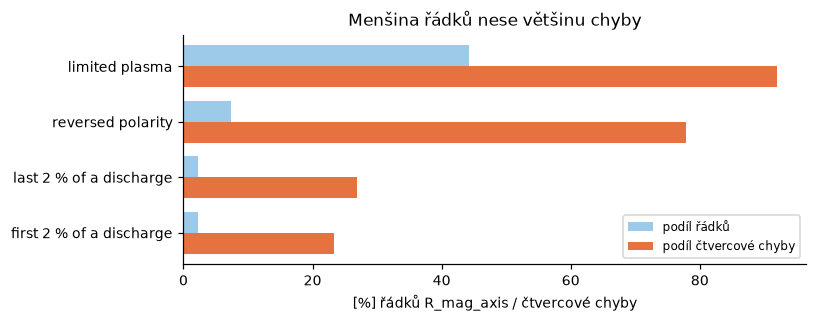

In [9]:
rows = []
def grp(name, mae, rows_pct, sq_pct, ref_name, ref_mae):
    rows.append({"group": name, "rows %": rows_pct, "squared error %": sq_pct, "MAE [mm]": mae, "reference group": ref_name, "reference MAE [mm]": ref_mae, "MAE ratio": mae / ref_mae})
r = "R_mag_axis"
grp("limited plasma", cfg.loc[r, "MAE limited"], cfg.loc[r, "rows limited"], cfg.loc[r, "sq err limited"], "diverted", cfg.loc[r, "MAE diverted"])
grp("reversed polarity", pol.loc[r, "MAE positive current"], pol.loc[r, "rows positive current"], pol.loc[r, "sq err positive current"], "usual polarity", pol.loc[r, "MAE negative current"])
grp("last 2 % of a discharge", pos.loc[r, "MAE last 2 %"], pos.loc[r, "rows last 2 %"], pos.loc[r, "sq err last 2 %"], "middle 96 %", pos.loc[r, "MAE middle 96 %"])
grp("first 2 % of a discharge", pos.loc[r, "MAE first 2 %"], pos.loc[r, "rows first 2 %"], pos.loc[r, "sq err first 2 %"], "middle 96 %", pos.loc[r, "MAE middle 96 %"])
share = pd.DataFrame(rows).set_index("group")
show(share, P1 + "; target R_mag_axis")

fig, ax = plt.subplots(figsize=(7.5, 3)); y = np.arange(len(share)); h = 0.38
ax.barh(y - h/2, share["rows %"], h, label="podíl řádků", color="#9ecae9")
ax.barh(y + h/2, share["squared error %"], h, label="podíl čtvercové chyby", color="#e6733f")
ax.set_yticks(y); ax.set_yticklabels(share.index); ax.invert_yaxis(); ax.set_xlabel("[%] řádků R_mag_axis / čtvercové chyby")
ax.legend(fontsize=8, loc="lower right"); ax.set_title("Menšina řádků nese většinu chyby"); plt.tight_layout(); plt.show()

### 3.1 Bod limiteru

In [10]:
lim = overall.loc[["R_limiter", "Z_limiter"], ["unit", "MAE", "median", "p99", "nRMSE"]].copy()
lim["spread (SD) [mm]"] = spread.loc[["R_limiter", "Z_limiter"], "standard deviation"]
lim["MAE / SD"] = lim["MAE"] / lim["spread (SD) [mm]"]
lim["MAE first 2 % [mm]"] = pos.loc[["R_limiter", "Z_limiter"], "MAE first 2 %"]
lim["MAE middle [mm]"] = pos.loc[["R_limiter", "Z_limiter"], "MAE middle 96 %"]
show(lim, P1 + "; bod limiteru existuje jen v limiterových řádcích (19 012 ze 42 972)")

rl = numeric(table(F_DIST, "R_limiter (mm)", has=["quintile"]).rename(columns={"quintile": "q"}), text=("range of the true value",)).dropna(subset=["MAE"])
display(Markdown(
    f"**Čtení.** Bod limiteru je nejslabší cíl: nRMSE {overall.loc['R_limiter','nRMSE']:.2f} (R) a {overall.loc['Z_limiter','nRMSE']:.2f} (Z) proti "
    f"{overall.loc[['R_mag_axis','Z_mag_axis','R_x_point'],'nRMSE'].min():.2f} to {overall.loc[['R_mag_axis','Z_mag_axis','R_x_point'],'nRMSE'].max():.2f} "
    f"u osy a X bodu. Jeho R se odhaduje nejhůř na ZAČÁTKU výboje ({lim.loc['R_limiter','MAE first 2 % [mm]']:.1f} mm v prvních 2 % "
    f"proti {lim.loc['R_limiter','MAE middle [mm]']:.1f} mm uprostřed) a u jeho vzácných velkých hodnot "
    f"(nejvyšší kvintil, {rl.loc['Q5','range of the true value']} mm: MAE {rl.loc['Q5','MAE']:.1f} mm proti {rl.loc['Q4','MAE']:.1f} mm v kvintilu pod ním, "
    f"{rl.loc['Q5','sq err']:.1f} % čtvercové chyby na {rl.loc['Q5','rows']:.1f} % řádků). "
    f"Bod limiteru existuje jen tam, kde se plazma dotýká stěny, takže je definován u {overall.loc['R_limiter','n']/overall.loc['R_mag_axis','n']*100:.0f} % řádků a je to spíš dotyk se stěnou než hladký rys tvaru. "
    f"Kde hranice klouže podél téměř tečné stěny, může malá změna rovnováhy posunout dotyk daleko, takže část velké chyby může pocházet z definice toho bodu (hypotéza, netestováno); "
    f"vzdálenost plazmatu od stěny, kterou regulátor potřebuje, se neměřila."))

Protokol: baseline MLP 256-256-128 on 24 inputs, 60 epochs, 5-fold GroupKFold by discharge, out-of-fold, 42,972 rows of 149 discharges (`distribution.md`); bod limiteru existuje jen v limiterových řádcích (19 012 ze 42 972)
          unit  MAE  median  p99  nRMSE  spread (SD) [mm]  MAE / SD  MAE first 2 % [mm]  MAE middle [mm]
target                                                                                                  
R_limiter   mm 10.8    2.64  145  0.318              89.6     0.121                52.6             8.28
Z_limiter   mm 22.3    9.32  171  0.273               153     0.145                  14             22.8



**Čtení.** Bod limiteru je nejslabší cíl: nRMSE 0,32 (R) a 0,27 (Z) proti 0,08 to 0,16 u osy a X bodu. Jeho R se odhaduje nejhůř na ZAČÁTKU výboje (52,6 mm v prvních 2 % proti 8,3 mm uprostřed) a u jeho vzácných velkých hodnot (nejvyšší kvintil, 447,4 to 771,5 mm: MAE 24,1 mm proti 7,4 mm v kvintilu pod ním, 58,6 % čtvercové chyby na 20,6 % řádků). Bod limiteru existuje jen tam, kde se plazma dotýká stěny, takže je definován u 44 % řádků a je to spíš dotyk se stěnou než hladký rys tvaru. Kde hranice klouže podél téměř tečné stěny, může malá změna rovnováhy posunout dotyk daleko, takže část velké chyby může pocházet z definice toho bodu (hypotéza, netestováno); vzdálenost plazmatu od stěny, kterou regulátor potřebuje, se neměřila.

## 4. Co se s tím udělalo (protokol P2): změřeno, jedna reakce vyzkoušena, nenasazena

`distribution.md` měří nerovnoměrnost a výslovně říká, že se tam **neuplatnily žádné stratifikované foldy ani převažování**. Jedna reakce, která se
vyzkoušela, mění jen **vstupy**, aby se nasazením nemuselo měnit dělení dat: znaménko 16 signálů cívek se používá k tomu, aby se výboj s obrácenou
polaritou převedl na obvyklý (`signcanon.md`, skript v `analysis/` na receptuře `cand` z `final_evaluation.py`).
Protokol: 5násobný GroupKFold uvnitř 119 vývojových výbojů (34 211 řádků), 3 semínka, párově (každý běh s kanonizací sdílí fold, semínko a odložené
výboje s obyčejným během), pak 30 odložených výbojů, hodnoceno jednou pro každý konečný model.

Protokol: indikátor `-sign(součet IPR01..16)` proti znaménku proudu plazmatu; vývojové řádky
                                           rows agree with sign(plasma_current)  fraction
check                                                                                    
clean inputs, development rows           34,211                          34,211  1.000000
provided noisy inputs, development rows  34,211                          34,211  1.000000

spočteno z tabulky poměrů: obrácené řádky +64.2 % lepší, obvyklé řádky +20.2 % horší; verdikt souboru: +64.2 % a +20.2 %
Protokol: vývojová sada (P2), souhrnné MAE běhu s kanonizací dělené obyčejným během; pod 1 = kanonizace lepší
                    unit  overall  reversed (positive current)  usual (negative current)
target                                                                                  
R_mag_axis            mm    0.851                        0.326                      1.23
Z_mag_axis            mm    0.776               

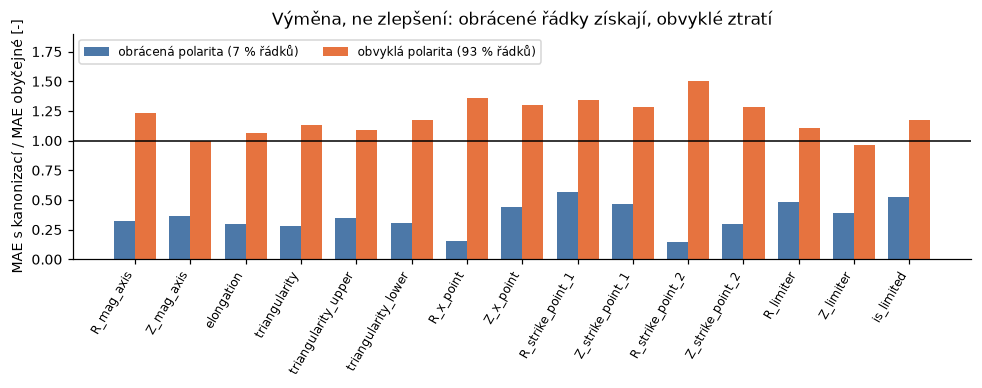

In [11]:
F_SC = "signcanon.md"
ind = table(F_SC, "The indicator", has=["agree with sign(plasma_current)"])
show(ind.set_index("check"), "indikátor `-sign(součet IPR01..16)` proti znaménku proudu plazmatu; vývojové řádky", fmt="{:.6g}")

ratio = numeric(table(F_SC, "Development result", has=["overall", "positive current", "negative current"]))
ratio.columns = ["unit", "overall", "reversed (positive current)", "usual (negative current)"]
shape = [t for t in ratio.index if t != "plasma_current"]  # 15 cílů tvaru; proud je lineární fit a nemění se
gain_rev = 1 - ratio.loc[shape, "reversed (positive current)"].mean()
cost_usual = ratio.loc[shape, "usual (negative current)"].mean() - 1
verdict = section(F_SC, "Verdict")
file_gain = float(re.search(r"Reversed-polarity rows.*?\*\*\+([\d.]+)%", verdict).group(1))
file_cost = float(re.search(r"Negative-current majority.*?\*\*\+([\d.]+)%", verdict).group(1))
print(f"spočteno z tabulky poměrů: obrácené řádky {gain_rev*100:+.1f} % lepší, obvyklé řádky {cost_usual*100:+.1f} % horší; verdikt souboru: +{file_gain} % a +{file_cost} %")
assert abs(gain_rev*100 - file_gain) < 0.2 and abs(cost_usual*100 - file_cost) < 0.2

show(ratio.loc[shape], "vývojová sada (P2), souhrnné MAE běhu s kanonizací dělené obyčejným během; pod 1 = kanonizace lepší")
fig, ax = plt.subplots(figsize=(9, 3.6)); x = np.arange(len(shape)); w = 0.38
ax.bar(x - w/2, ratio.loc[shape, "reversed (positive current)"], w, label=f"obrácená polarita ({pol.loc['R_mag_axis', 'rows positive current']:.0f} % řádků)", color="#4c78a8")
ax.bar(x + w/2, ratio.loc[shape, "usual (negative current)"], w, label=f"obvyklá polarita ({100 - pol.loc['R_mag_axis', 'rows positive current']:.0f} % řádků)", color="#e6733f")
ax.axhline(1, color="k", lw=1); ax.set_xticks(x); ax.set_xticklabels(shape, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("MAE s kanonizací / MAE obyčejné [-]"); ax.set_title("Výměna, ne zlepšení: obrácené řádky získají, obvyklé ztratí"); ax.set_ylim(0, 1.9); ax.legend(fontsize=8, ncol=2, loc="upper left")
plt.tight_layout(); plt.show()

In [12]:
seeds = table(F_SC, "Development result", has=["variant", "mean"]).set_index("variant")
all16 = seeds["mean"].map(float)
agg_gain = 1 - all16["canon"] / all16["plain"]
locked = numeric(table(F_SC, "Locked test set", has=["plain", "canon", "ratio"]))
worse = locked.index[locked["ratio"] > 1.02].tolist()
lm = re.search(r"all16 plain (\d+\.\d+), canon (\d+\.\d+)", read(F_SC))
locked_all16 = (float(lm.group(1)), float(lm.group(2)))
show(seeds, "průměrná relativní chyba přes 16 cílů (`all16`), vývojová sada, po skupinách semínek", fmt="{:.4f}")
display(Markdown(
    f"**Čtení.** V průměru přes 15 cílů tvaru kanonizace snižuje chybu řádků s obrácenou polaritou o **{gain_rev*100:.0f} %** a zvyšuje chybu řádků s obvyklou polaritou "
    f"(většina, {100 - pol.loc['R_mag_axis','rows positive current']:.0f} %) o **{cost_usual*100:.0f} %**. Souhrn `all16` se zlepší o {agg_gain*100:.0f} % jen proto, že mu dominuje těžký chvost obrácených výbojů; "
    f"toto číslo přehání přínos a neuvádí se jako zlepšení. Na 30 odložených výbojích (jen 2 z nich jsou obrácené, realističtější směs) je `all16` "
    f"{locked_all16[0]:.4f} obyčejné proti {locked_all16[1]:.4f} s kanonizací, skoro nic, a {len(worse)} z {len(locked)} cílů je horších o víc než 2 %: {', '.join(worse)}. "
    f"**Nenasazeno.** Verdikt v souboru zní: nasadit jen tehdy, když se musí obsluhovat výboje s obrácenou polaritou. Nasazený model se učí na surových vstupech."))

Protokol: průměrná relativní chyba přes 16 cílů (`all16`), vývojová sada, po skupinách semínek
        seeds 0 seeds 1 seeds 2    mean
variant                                
plain    0.0912  0.0994  0.0954  0.0953
canon    0.0638  0.0639  0.0648  0.0642



**Čtení.** V průměru přes 15 cílů tvaru kanonizace snižuje chybu řádků s obrácenou polaritou o **64 %** a zvyšuje chybu řádků s obvyklou polaritou (většina, 93 %) o **20 %**. Souhrn `all16` se zlepší o 33 % jen proto, že mu dominuje těžký chvost obrácených výbojů; toto číslo přehání přínos a neuvádí se jako zlepšení. Na 30 odložených výbojích (jen 2 z nich jsou obrácené, realističtější směs) je `all16` 0,0590 obyčejné proti 0,0573 s kanonizací, skoro nic, a 10 z 16 cílů je horších o víc než 2 %: Z_mag_axis, triangularity, triangularity_upper, triangularity_lower, Z_x_point, R_strike_point_1, Z_strike_point_1, R_limiter, Z_limiter, is_limited. **Nenasazeno.** Verdikt v souboru zní: nasadit jen tehdy, když se musí obsluhovat výboje s obrácenou polaritou. Nasazený model se učí na surových vstupech.

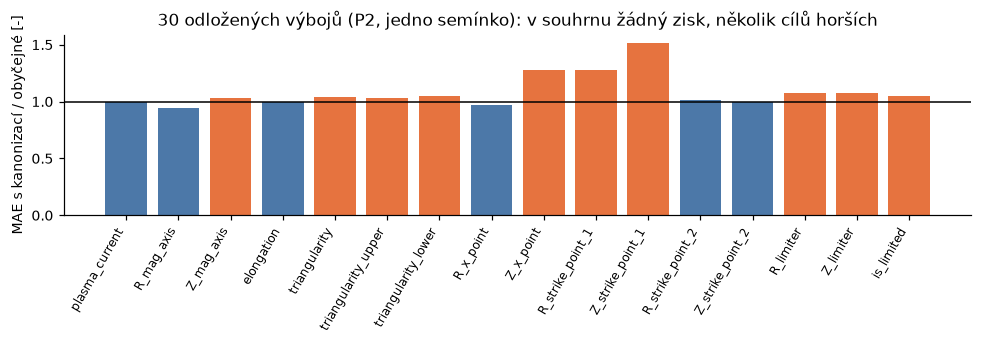

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.2)); x = np.arange(len(locked))
ax.bar(x, locked["ratio"], color=np.where(locked["ratio"] > 1.02, "#e6733f", "#4c78a8"))
ax.axhline(1, color="k", lw=1); ax.set_xticks(x); ax.set_xticklabels(locked.index, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("MAE s kanonizací / obyčejné [-]"); ax.set_title("30 odložených výbojů (P2, jedno semínko): v souhrnu žádný zisk, několik cílů horších")
plt.tight_layout(); plt.show()

### 4.1 Nasazený model na týchž skupinách a proč je odložená sada snadná

Protokol: P2: trained on 119 development discharges, scored on 30 discharges kept aside (8,761 rows), clean inputs, one seed (`final-evaluation.md`); cíl R_mag_axis, MAE [mm]
                              rows  discharges  baseline  candidate  candidate / baseline
divertor                      5207          30     0.202     0.0929                0.4599
limited                       3554          30      0.46      0.192                0.4174
usual polarity (negative)     8170          28     0.257       0.11                 0.428
reversed polarity (positive)   591           2     0.998      0.454                0.4549
first 2 % of the discharge     189          30      1.65      0.538                0.3261
middle                        8383          30     0.256      0.114                0.4453
last 2 % of the discharge      189          30      1.21      0.578                0.4777



Protokol: vývojová = souhrn mimo učicí sadu přes 119 výbojů, odložená = 30 výbojů (`final-evaluation.md`)
                           development CV, R axis [mm]  kept aside, R axis [mm]  development CV, mean nRMSE (16)  kept aside, mean nRMSE (16)  nRMSE lower on the kept-aside set by %
baseline MLP                                     0.479                    0.307                           0.1228                       0.0803                                   34.61
shipped candidate (clean)                         0.23                    0.133                           0.0912                        0.059                                   35.31



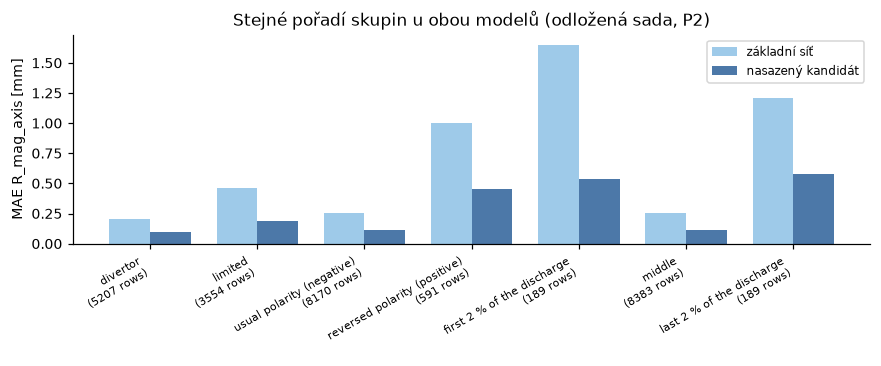

In [14]:
F_FIN = "final-evaluation.md"
P2 = "P2: trained on 119 development discharges, scored on 30 discharges kept aside (8,761 rows), clean inputs, one seed (`final-evaluation.md`)"

def breakdown(prefix, col_base="baseline MLP clean", col_cand="candidate, plain clean", target="R_mag_axis"):
    for h, df in md_tables(F_FIN):
        if h.startswith(prefix):
            n = re.search(r"\((\d+) rows, (\d+) discharges\)", h)
            d = numeric(df)
            return {"rows": int(n.group(1)), "discharges": int(n.group(2)), "baseline": d.loc[target, col_base], "candidate": d.loc[target, col_cand]}
    raise KeyError(prefix)

groups = {"divertor": "configuration: divertor", "limited": "configuration: limited", "usual polarity (negative)": "polarity: negative", "reversed polarity (positive)": "polarity: positive",
          "first 2 % of the discharge": "relative time: first 2 %", "middle": "relative time: middle", "last 2 % of the discharge": "relative time: last 2 %"}
lk = pd.DataFrame({g: breakdown(p) for g, p in groups.items()}).T
lk["candidate / baseline"] = lk["candidate"] / lk["baseline"]
assert (lk.loc["reversed polarity (positive)", "discharges"], lk.loc["reversed polarity (positive)", "rows"]) == (2, 591)  # citováno v markdownu výše
show(lk, P2 + "; cíl R_mag_axis, MAE [mm]", fmt="{:.4g}")

dev = numeric(table(F_FIN, "Development set: pooled out-of-fold scores"), text=("inputs", "recipe"))
dev.index.name = "recipe"
devc = dev[dev["inputs"] == "clean"]
loc_base = numeric(table(F_FIN, "baseline MLP, clean inputs")); loc_cand = numeric(table(F_FIN, "candidate, plain, clean inputs"))
nr = lambda pre: float(re.search(r"mean nRMSE over 16 targets ([\d.]+)", [h for h, _ in md_tables(F_FIN) if h.startswith(pre)][0]).group(1))
cmp_ = pd.DataFrame({
    "development CV, R axis [mm]": [devc.loc["baseline MLP", "R_mag_axis MAE"], devc.loc["candidate, plain", "R_mag_axis MAE"]],
    "kept aside, R axis [mm]": [loc_base.loc["R_mag_axis", "MAE"], loc_cand.loc["R_mag_axis", "MAE"]],
    "development CV, mean nRMSE (16)": [devc.loc["baseline MLP", "mean nRMSE (16)"], devc.loc["candidate, plain", "mean nRMSE (16)"]],
    "kept aside, mean nRMSE (16)": [nr("baseline MLP, clean inputs"), nr("candidate, plain, clean inputs")]}, index=["baseline MLP", "shipped candidate (clean)"])
cmp_["nRMSE lower on the kept-aside set by %"] = (1 - cmp_["kept aside, mean nRMSE (16)"] / cmp_["development CV, mean nRMSE (16)"]) * 100
show(cmp_, "vývojová = souhrn mimo učicí sadu přes 119 výbojů, odložená = 30 výbojů (`final-evaluation.md`)", fmt="{:.4g}")

fig, ax = plt.subplots(figsize=(8, 3.4)); x = np.arange(len(lk)); w = 0.38
ax.bar(x - w/2, lk["baseline"], w, label="základní síť", color="#9ecae9"); ax.bar(x + w/2, lk["candidate"], w, label="nasazený kandidát", color="#4c78a8")
ax.set_xticks(x); ax.set_xticklabels([f"{g}\n({int(n)} rows)" for g, n in zip(lk.index, lk["rows"])], fontsize=7, rotation=30, ha="right")
ax.set_ylabel("MAE R_mag_axis [mm]"); ax.set_title("Stejné pořadí skupin u obou modelů (odložená sada, P2)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Neobvyklé tvary: vynechat celou rodinu (protokol P3)

Zdroj: `unusual-shapes.md` (`analysis/unusual_shapes.py`, uložený obrázek `unusual-shapes.png`).
Každý výboj se popíše mediánem elongace a mediánem triangularity; KMeans na pořadích obou hodnot vytvoří rodiny. Pro každou rodinu se síť
učí na všech ostatních výbojích a testuje na rodině. Reference je chyba na **týchž výbojích** při obvyklém náhodném 5násobném dělení, takže faktor
způsobuje neviděný tvar a ne volba výbojů. Síť je společná síť 256-256-128, 60 epoch, jedna inicializace na skupinu. 18 neobvyklých výbojů jsou ty s nízkou mediánovou elongací; hodnoty elongace pod 1 jsou pro tokamakové plazma neobvyklé a vzorec organizátorů tu není zaznamenán, takže je fyzikálně neinterpretujeme (ověřit s ústavem).

*Citováno z `results/unusual-shapes.md`:*

Nearly all discharges lie in one tight group (median elongation 1.75 to 1.82, triangularity 0.33 to 0.40). 18 discharges are really different
(median elongation 1.0 to 1.74, triangularity 0.02 to 0.33); they all fall into cluster 0, and they are 18 of the 23 discharges of the low elongation group. Clusters 1 to 3 are therefore subgroups
of ordinary shapes. The high triangularity group (median 0.38 against 0.36 for everything) is only the upper edge of the ordinary group and **is not
a rare shape**.

rozsah = (náhodné dělení, bez rodiny) a podíl = faktor, v rámci zaokrouhlení: True
Protokol: P3: family held out, network trained on all other discharges; reference = same discharges in the random 5-fold split (`unusual-shapes.md`)
                                                        discharges R axis [mm] ref->out Z axis [mm] ref->out elongation [-] ref->out limiter R [mm] ref->out
Held out                                                                                                                                                    
cluster 0 (contains the 18 odd shapes)                        34.0          0.53 -> 1.1         0.48 -> 0.99        0.0075 -> 0.0136            11.2 -> 34.1
cluster 1                                                     39.0         0.43 -> 0.75         0.48 -> 0.76        0.0063 -> 0.0081            10.3 -> 11.5
cluster 2                                                     33.0         0.38 -> 0.44         0.38 -> 0.47        0.0056 -> 0.0064        

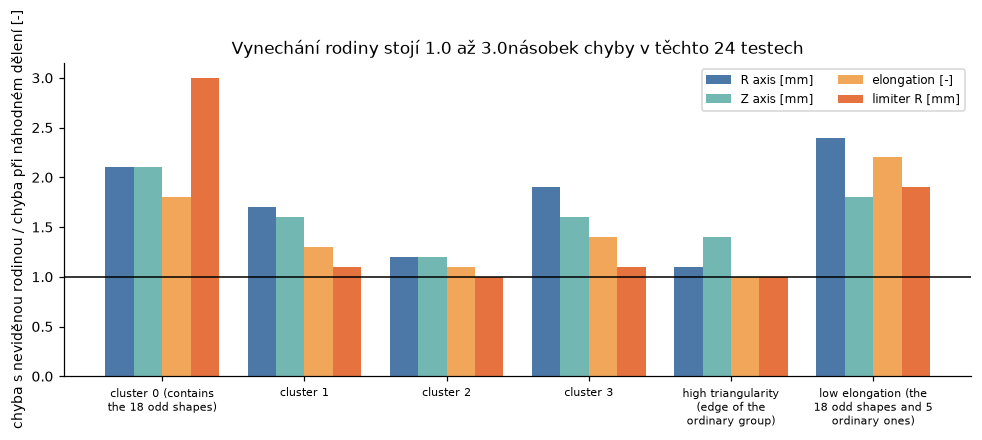

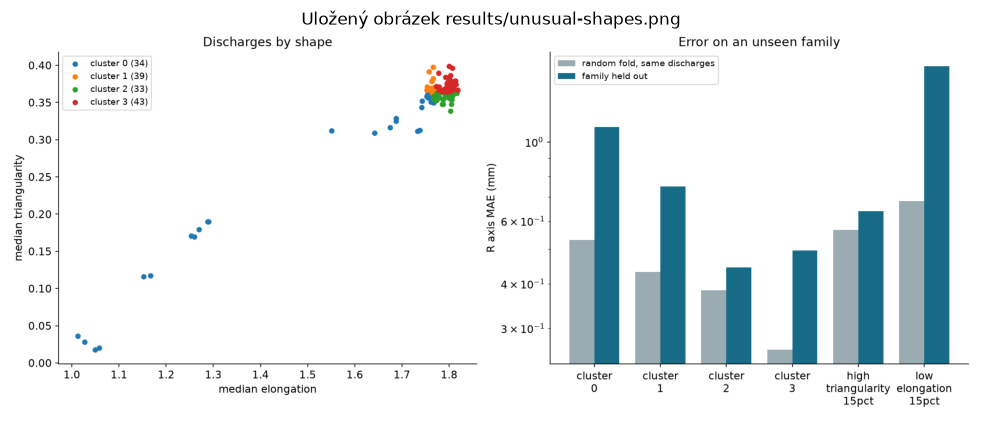

In [15]:
import textwrap
F_US = "unusual-shapes.md"
P3 = "P3: family held out, network trained on all other discharges; reference = same discharges in the random 5-fold split (`unusual-shapes.md`)"
quote(section(F_US, "What the 149 discharges look like"), F_US)
n_odd = int(re.search(r"(\d+) discharges are really different", section(F_US, "What the 149 discharges look like")).group(1))
assert n_odd == 18, n_odd  # citováno v textu tohoto oddílu a v odpovědi

us = table(F_US, "Result", has=["Held out"]).set_index("Held out")
cols = {"R axis (mm)": "R axis [mm]", "Z axis (mm)": "Z axis [mm]", "elongation": "elongation [-]", "limiter R (mm)": "limiter R [mm]"}
pat = re.compile(r"([\d.]+) to ([\d.]+) \(([\d.]+)x\)")
parsed = {name: us[c].map(lambda s: tuple(map(float, pat.match(s).groups()))) for c, name in cols.items()}
factor = pd.DataFrame({n: s.map(lambda t: t[2]) for n, s in parsed.items()})
ref = pd.DataFrame({n: s.map(lambda t: t[0]) for n, s in parsed.items()})
out = pd.DataFrame({n: s.map(lambda t: t[1]) for n, s in parsed.items()})
# První číslo každé buňky je referenční chyba, druhé chyba bez rodiny: jejich podíl musí odpovídat uvedenému faktoru.
ok = ((out / ref - factor).abs() <= 0.12).values.all()
print("rozsah = (náhodné dělení, bez rodiny) a podíl = faktor, v rámci zaokrouhlení:", ok)
assert ok
fam = pd.concat({"discharges": us["Discharges"].map(float), **{f"{n} ref->out": (ref[n].map("{:.3g}".format) + " -> " + out[n].map("{:.3g}".format)) for n in cols.values()}}, axis=1)
print("Protokol:", P3); print(fam.to_string()); print()
show(factor.add_prefix("x "), P3 + "; faktor = bez rodiny / náhodné dělení, tytéž výboje", fmt="{:.1f}")

fig, ax = plt.subplots(figsize=(9, 3.8)); x = np.arange(len(factor)); w = 0.2
for i, (n, colr) in enumerate(zip(factor.columns, ["#4c78a8", "#72b7b2", "#f2a65a", "#e6733f"])):
    ax.bar(x + (i - 1.5) * w, factor[n], w, label=n, color=colr)
ax.axhline(1, color="k", lw=1); ax.set_xticks(x); ax.set_xticklabels([textwrap.fill(s, 20) for s in factor.index], fontsize=7)
ax.set_ylabel("chyba s neviděnou rodinou / chyba při náhodném dělení [-]"); ax.set_title(f"Vynechání rodiny stojí {factor.values.min():.1f} až {factor.values.max():.1f}násobek chyby v těchto {factor.size} testech"); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

img = plt.imread(RES / "unusual-shapes.png"); READ.add("unusual-shapes.png")
fig, ax = plt.subplots(figsize=(9, 5)); ax.imshow(img); ax.axis("off"); ax.set_title("Uložený obrázek results/unusual-shapes.png"); plt.tight_layout(); plt.show()

In [16]:
odd = us.index[us.index.str.startswith("low elongation")][0]
c0 = us.index[us.index.str.startswith("cluster 0")][0]
hi = us.index[us.index.str.startswith("high triangularity")][0]
display(Markdown(
    f"**Čtení.** Vynechání rodiny zvětší chybu {factor.values.min():.1f} to {factor.values.max():.1f} krát, "
    f"v mediánu přes {factor.size} hodnot výše {np.median(factor.values):.1f}krát. Rodina tvořená hlavně podivnými tvary ('{odd}') jde z "
    f"{ref.loc[odd,'R axis [mm]']:.2f} to {out.loc[odd,'R axis [mm]']:.2f} mm u radiální osy a z {ref.loc[odd,'elongation [-]']:.4f} na "
    f"{out.loc[odd,'elongation [-]']:.4f} u elongace a shluk 0 ('{c0}') má největší faktor u limiteru, {factor.loc[c0,'limiter R [mm]']:.1f}krát. "
    f"Rodina s vysokou triangularitou je jen horní okraj běžné skupiny a není to vzácný tvar; její faktory jsou {factor.loc[hi].min():.1f} to {factor.loc[hi].max():.1f}."))
quote(section(F_US, "Limits"), F_US)
# Po sepsání té zprávy se 18 nejpodivnějších výbojů vynechalo i samotných; jejich čísla se čtou z vlastního uloženého souboru.
F_HO = "unusual-heldout.md"
ho = numeric(table(F_HO, "odd18"))
early = re.search(r"(\d+) of the (\d+) ids lie in the lowest quarter", read(F_HO)).groups()
ho_r, ho_e = ho.loc["R_mag_axis"], ho.loc["elongation"]
display(Markdown(
    f"**{early[1]} nejpodivnějších výbojů vynechaných samotných** (`{F_HO}`, základní síť, 3 semínka): radiální osa {ho_r['MAE random folds']:.2f} mm v náhodných foldech na týchž výbojích proti "
    f"{ho_r['MAE left out']:.2f} mm s jejich vynecháním ({ho_r['factor']:.1f}krát), elongace {ho_e['MAE random folds']:.4f} against {ho_e['MAE left out']:.4f} ({ho_e['factor']:.1f}krát). "
    f"{early[0]} z {early[1]} čísel leží v nejnižší čtvrtině čísel výbojů, takže faktor míchá tvar s ranou částí pořadí kampaně. "
    f"Pořád to není test tvarů mimo rozsah dat."))

**Čtení.** Vynechání rodiny zvětší chybu 1,0 to 3,0 krát, v mediánu přes 24 hodnot výše 1,5krát. Rodina tvořená hlavně podivnými tvary ('low elongation (the 18 odd shapes and 5 ordinary ones)') jde z 0,68 to 1,63 mm u radiální osy a z 0,0100 na 0,0225 u elongace a shluk 0 ('cluster 0 (contains the 18 odd shapes)') má největší faktor u limiteru, 3,0krát. Rodina s vysokou triangularitou je jen horní okraj běžné skupiny a není to vzácný tvar; její faktory jsou 1,0 to 1,4.

*Citováno z `results/unusual-shapes.md`:*

- The random split is itself optimistic: discharge ids are chronological, so neighbours of every test discharge are in training
  (`docs/internal/review-findings.md`). The factors measure the loss from removing a whole family, not the total error on a new tokamak scenario.
- Only 18 discharges are truly unusual and they were never held out alone (cluster 0 and the low elongation group mix them with 16 and 5 ordinary ones),
  and the extreme elongation near 1.0 was never tested as an unseen extreme. The result says nothing about shapes outside the range of the data.
- One initialization per group, no repeated runs; with 23 to 43 discharges per group a factor of 1.1x to 1.3x is within noise.

**18 nejpodivnějších výbojů vynechaných samotných** (`unusual-heldout.md`, základní síť, 3 semínka): radiální osa 0,91 mm v náhodných foldech na týchž výbojích proti 2,26 mm s jejich vynecháním (2,5krát), elongace 0,0122 against 0,0219 (1,8krát). 14 z 18 čísel leží v nejnižší čtvrtině čísel výbojů, takže faktor míchá tvar s ranou částí pořadí kampaně. Pořád to není test tvarů mimo rozsah dat.

## 6. Kontrola původu a odpověď

In [17]:
missing, n_read, git_ok = tracked_check()
print(f"přečteno {n_read} souborů s výsledky:", ", ".join(sorted(READ)))
print("všechny jsou v gitu:", (not missing) if git_ok else "git tu není dostupný, nelze zkontrolovat")
assert not missing, missing

přečteno 7 souborů s výsledky: data-checks.md, distribution.md, final-evaluation.md, signcanon.md, unusual-heldout.md, unusual-shapes.md, unusual-shapes.png
všechny jsou v gitu: True


In [18]:
display(Markdown(f"""
## Odpověď

**Ano, data jsou nerovnoměrná a hlavní průměr to skrývá.** U polohy radiální osy (základní síť, mimo učicí sadu, P1) je průměrný absolutní rozdíl od referenční rekonstrukce {overall.loc['R_mag_axis','MAE']:.2f} mm,
medián {overall.loc['R_mag_axis','median']:.2f} mm, 99 % řádků je pod {overall.loc['R_mag_axis','p99']:.1f} mm a nejhorší řádek má {overall.loc['R_mag_axis','max']:.0f} mm.
Limiterové plazma tvoří {cfg.loc['R_mag_axis','rows limited']:.0f} % řádků a nese {cfg.loc['R_mag_axis','sq err limited']:.0f} % čtvercové chyby ({share.loc['limited plasma','MAE ratio']:.1f}násobek divertorové chyby);
{n_pos} výbojů s kladným proudem („obrácených“) je {pol.loc['R_mag_axis','rows positive current']:.1f} % řádků a nese {pol.loc['R_mag_axis','sq err positive current']:.0f} %;
posledních 2 % výboje je {pos.loc['R_mag_axis','rows last 2 %']:.0f} % řádků a nese {pos.loc['R_mag_axis','sq err last 2 %']:.0f} %. Bod limiteru je nejslabší cíl
(nRMSE {overall.loc['R_limiter','nRMSE']:.2f} a {overall.loc['Z_limiter','nRMSE']:.2f}).

**Co jsme s tím udělali.** Nerovnoměrnost je změřená, ne opravená převažováním ani stratifikovanými foldy. Jediná vyzkoušená reakce, převedení obrácené polarity na obvyklou podle znaménka signálů cívek,
snižuje chybu obrácených řádků o {gain_rev*100:.0f} % a zvyšuje chybu obvyklých o {cost_usual*100:.0f} %; je to výměna, **nenasazuje se** a hodí se jen tehdy, když se musí obsluhovat výboje s obrácenou polaritou.
30 odložených výbojů je snazších než vývojový průměr (nRMSE o {cmp_.loc['shipped candidate (clean)','nRMSE lower on the kept-aside set by %']:.0f} % nižší u nasazeného modelu) a obsahuje jen {lk.loc['reversed polarity (positive)','discharges']:.0f} obrácené výboje, takže to nemůže rozhodnout.

**Neobvyklé tvary.** Celá rodina tvarů vynechaná z učení stojí {factor.values.min():.1f} až {factor.values.max():.1f}násobek chyby (medián {np.median(factor.values):.1f}krát), v těchto testech žádný kolaps (není to obecné tvrzení); ale skutečně neobvyklých je jen {n_odd} výbojů; když se vynechají samotné (základní síť), chyba radiální osy vzroste {ho_r['factor']:.1f}krát, smíchaná s jejich ranou polohou v pořadí kampaně; náhodné dělení je samo optimistické (čísla výbojů zřejmě sledují čas; organizátoři nepotvrdili) a netvrdí se nic o tvarech mimo rozsah dat.
"""))


## Odpověď

**Ano, data jsou nerovnoměrná a hlavní průměr to skrývá.** U polohy radiální osy (základní síť, mimo učicí sadu, P1) je průměrný absolutní rozdíl od referenční rekonstrukce 0,38 mm,
medián 0,15 mm, 99 % řádků je pod 3,7 mm a nejhorší řádek má 64 mm.
Limiterové plazma tvoří 44 % řádků a nese 92 % čtvercové chyby (2,3násobek divertorové chyby);
16 výbojů s kladným proudem („obrácených“) je 7,4 % řádků a nese 78 %;
posledních 2 % výboje je 2 % řádků a nese 27 %. Bod limiteru je nejslabší cíl
(nRMSE 0,32 a 0,27).

**Co jsme s tím udělali.** Nerovnoměrnost je změřená, ne opravená převažováním ani stratifikovanými foldy. Jediná vyzkoušená reakce, převedení obrácené polarity na obvyklou podle znaménka signálů cívek,
snižuje chybu obrácených řádků o 64 % a zvyšuje chybu obvyklých o 20 %; je to výměna, **nenasazuje se** a hodí se jen tehdy, když se musí obsluhovat výboje s obrácenou polaritou.
30 odložených výbojů je snazších než vývojový průměr (nRMSE o 35 % nižší u nasazeného modelu) a obsahuje jen 2 obrácené výboje, takže to nemůže rozhodnout.

**Neobvyklé tvary.** Celá rodina tvarů vynechaná z učení stojí 1,0 až 3,0násobek chyby (medián 1,5krát), v těchto testech žádný kolaps (není to obecné tvrzení); ale skutečně neobvyklých je jen 18 výbojů; když se vynechají samotné (základní síť), chyba radiální osy vzroste 2,5krát, smíchaná s jejich ranou polohou v pořadí kampaně; náhodné dělení je samo optimistické (čísla výbojů zřejmě sledují čas; organizátoři nepotvrdili) a netvrdí se nic o tvarech mimo rozsah dat.
